# 03. DPA로 AES 한 바이트 복구하기

AES 첫 라운드의 중간값을 `SBox[평문[0] XOR 키 후보]`로 가정합니다. 각 키 후보에 대해 중간값의 한 비트가 0인 파형과 1인 파형을 나눈 뒤 두 그룹의 평균 차이를 계산합니다.

정답 후보로 분류했을 때만 실제 누설 시점에 큰 차이가 남습니다. 이번 데이터는 해밍 무게 누설을 넣어 만든 합성 파형입니다.

## AES 파형 만들기

서로 다른 평문 700개를 고정 키로 처리한 합성 파형을 만듭니다. `plaintexts`는 공격자가 알고 있는 입력이고 `traces`는 측정 파형입니다. `key`는 마지막에 복구 결과를 확인할 때만 사용합니다.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from cw_sca_tutorial.analysis import dpa_differences
from cw_sca_tutorial.synthetic import make_aes_dataset

dataset = make_aes_dataset(trace_count=700)
traces, plaintexts, key = dataset.traces, dataset.plaintexts, dataset.key
print(f"합성 파형: {traces.shape}, 실제 키 첫 바이트: 0x{key[0]:02x}")

합성 파형: (700, 700), 실제 키 첫 바이트: 0x2b


## 파형과 누설 위치 확인

왼쪽에는 개별 파형 8개를, 오른쪽에는 700개 파형의 평균을 그립니다. 빨간 점은 합성 데이터에 넣어 둔 바이트별 누설 위치입니다. 개별 파형에서는 잡음이 커 보이지만 평균에서는 반복되는 처리 구간이 드러납니다.

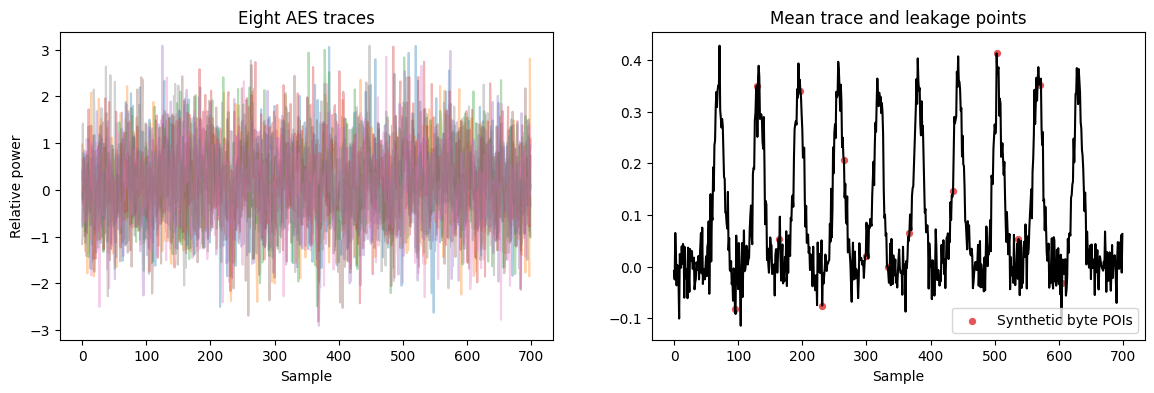

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(traces[:8].T, alpha=.35)
axes[0].set(title="Eight AES traces", xlabel="Sample", ylabel="Relative power")
axes[1].plot(traces.mean(axis=0), color="black")
axes[1].scatter(dataset.leakage_positions, traces.mean(axis=0)[dataset.leakage_positions], color="#e45756", s=18, label="Synthetic byte POIs")
axes[1].set(title="Mean trace and leakage points", xlabel="Sample")
axes[1].legend()
plt.show()

## 키 후보로 두 그룹 만들기

첫 번째 키 바이트의 후보 256개를 모두 시험합니다. 각 후보가 예측한 SBox 출력의 최하위 비트로 파형을 두 그룹으로 나누고 평균 차이를 계산합니다. `scores`에는 후보별 차이 파형의 가장 큰 절댓값이 들어갑니다.

In [3]:
differences = dpa_differences(traces, plaintexts, byte_index=0, bit=0)
scores = np.max(np.abs(differences), axis=1)
best = int(np.argmax(scores))
print(f"DPA 최상위 후보: 0x{best:02x} / 정답: 0x{key[0]:02x}")
assert best == int(key[0])

DPA 최상위 후보: 0x2b / 정답: 0x2b


## 256개 후보 비교

왼쪽 heatmap의 한 행이 한 키 후보입니다. 정답 행에서는 실제 누설 위치에 밝은 점이 생깁니다. 오른쪽에서는 정답 후보와 가장 강한 오답의 차이 파형을 겹쳐 피크 위치와 크기를 비교합니다.

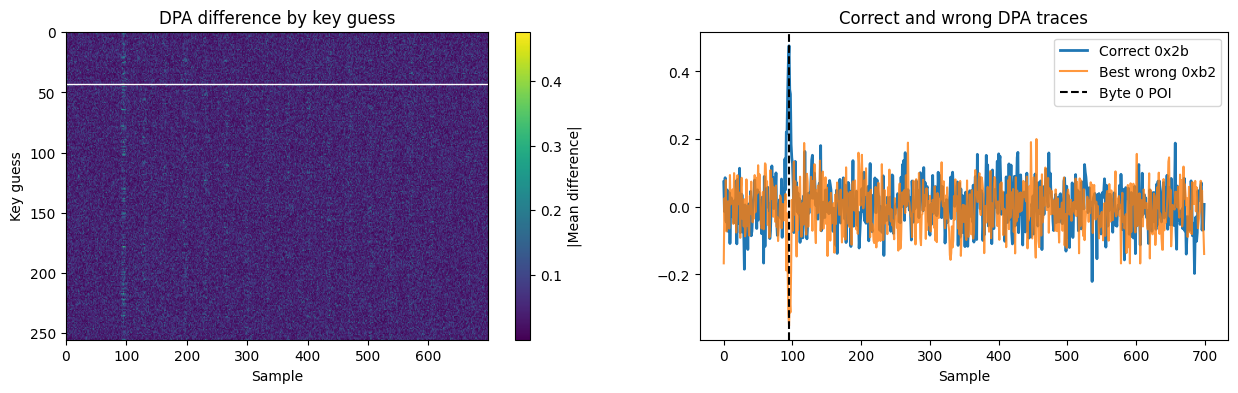

In [4]:
wrong = int(np.argsort(scores)[-2])
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
image = axes[0].imshow(np.abs(differences), aspect="auto", cmap="viridis")
axes[0].axhline(best, color="white", linewidth=1)
axes[0].set(title="DPA difference by key guess", xlabel="Sample", ylabel="Key guess")
fig.colorbar(image, ax=axes[0], label="|Mean difference|")
axes[1].plot(differences[best], label=f"Correct 0x{best:02x}", linewidth=2)
axes[1].plot(differences[wrong], label=f"Best wrong 0x{wrong:02x}", alpha=.8)
axes[1].axvline(dataset.leakage_positions[0], color="black", linestyle="--", label="Byte 0 POI")
axes[1].set(title="Correct and wrong DPA traces", xlabel="Sample")
axes[1].legend()
plt.show()

## 잘못된 시간 창과 비교하기

첫 50개 샘플에는 데이터 의존 누설을 넣지 않았습니다. 전체 구간의 정답 피크와 이 구간의 점수를 비교해 우연히 큰 값이 나온 경우를 구분합니다.

In [5]:
full_score = scores[int(key[0])]
wrong_window_score = np.max(np.abs(differences[int(key[0]), :50]))
print(f"정답 후보 전체 구간 점수: {full_score:.3f}")
print(f"정답 후보 잘못된 창 점수: {wrong_window_score:.3f}")
assert full_score > wrong_window_score

정답 후보 전체 구간 점수: 0.476
정답 후보 잘못된 창 점수: 0.185


## 정리

DPA는 키 후보가 예측한 한 비트로 파형을 나눕니다. 정답 후보라면 실제 누설 시점에서 두 그룹의 평균이 분리됩니다.